Shape: (12000, 41)
   variety_maturity_days  variety_max_yield  variety_avg_yield  land_area_ha  \
0                    107                4.4                3.2          4.47   
1                    104                9.3                5.7          1.51   
2                    123                8.1                5.1          2.39   
3                    107                4.4                3.2          0.38   
4                    122                8.2                5.6          2.53   

   fertilizer_kg_ha  historical_yield_tons_ha  temperature_avg  rainfall_mm  \
0             123.8                      3.74            26.91        181.3   
1              65.5                      6.37            26.07        126.1   
2             103.8                      5.38            25.93        247.8   
3             171.9                      2.43            22.43        289.6   
4              65.5                      4.62            26.38        321.9   

   humidity_avg  yield_to

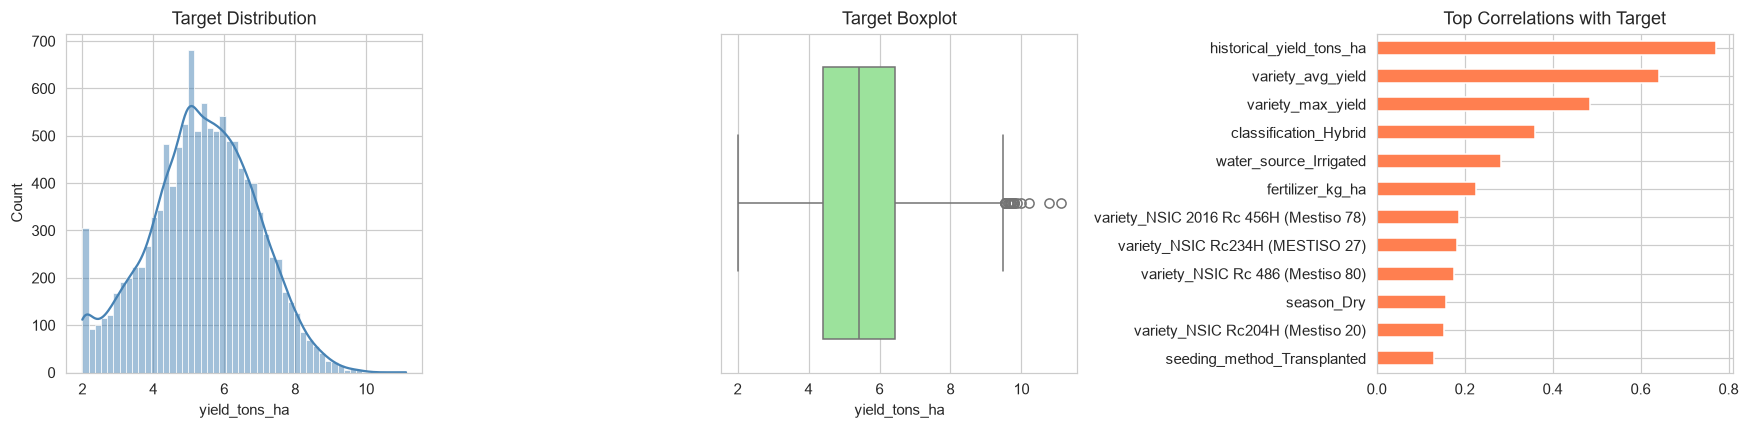

Train: (9600, 40)  |  Test: (2400, 40)
Fitting 5 folds for each of 60 candidates, totalling 300 fits

Best XGBoost params: {'colsample_bytree': np.float64(0.6976502088991097), 'gamma': np.float64(0.05048731265187917), 'learning_rate': np.float64(0.015938210978653514), 'max_depth': 3, 'min_child_weight': 4, 'n_estimators': 1736, 'reg_alpha': np.float64(0.03244612355449078), 'reg_lambda': np.float64(1.0078308278686894), 'subsample': np.float64(0.6987504251354405)}
Best CV RMSE: 0.4641

>>> Training XGBoost ...

>>> Training Gradient Boosting ...

>>> Training Random Forest ...

>>> Training Extra Trees ...

=== Test-set Performance ===
                     RMSE     MAE  MAPE (%)      R²
XGBoost            0.4716  0.3806    7.9149  0.8991
Gradient Boosting  0.4767  0.3842    8.0014  0.8969
Random Forest      0.5436  0.4307    8.9472  0.8660
Extra Trees        0.5662  0.4479    9.3188  0.8546


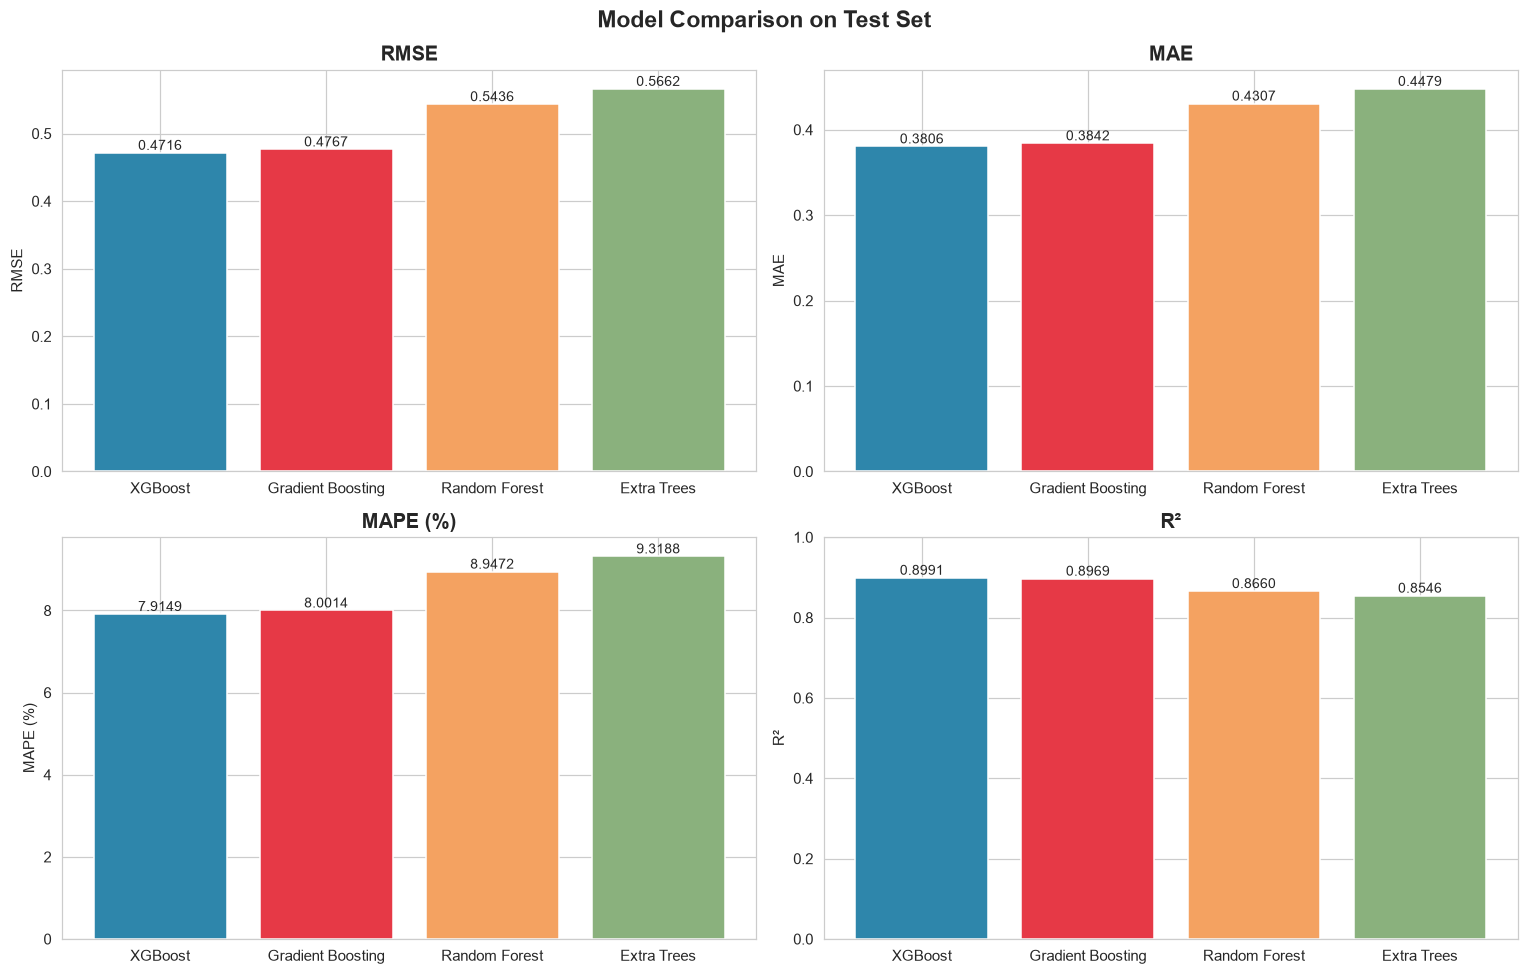

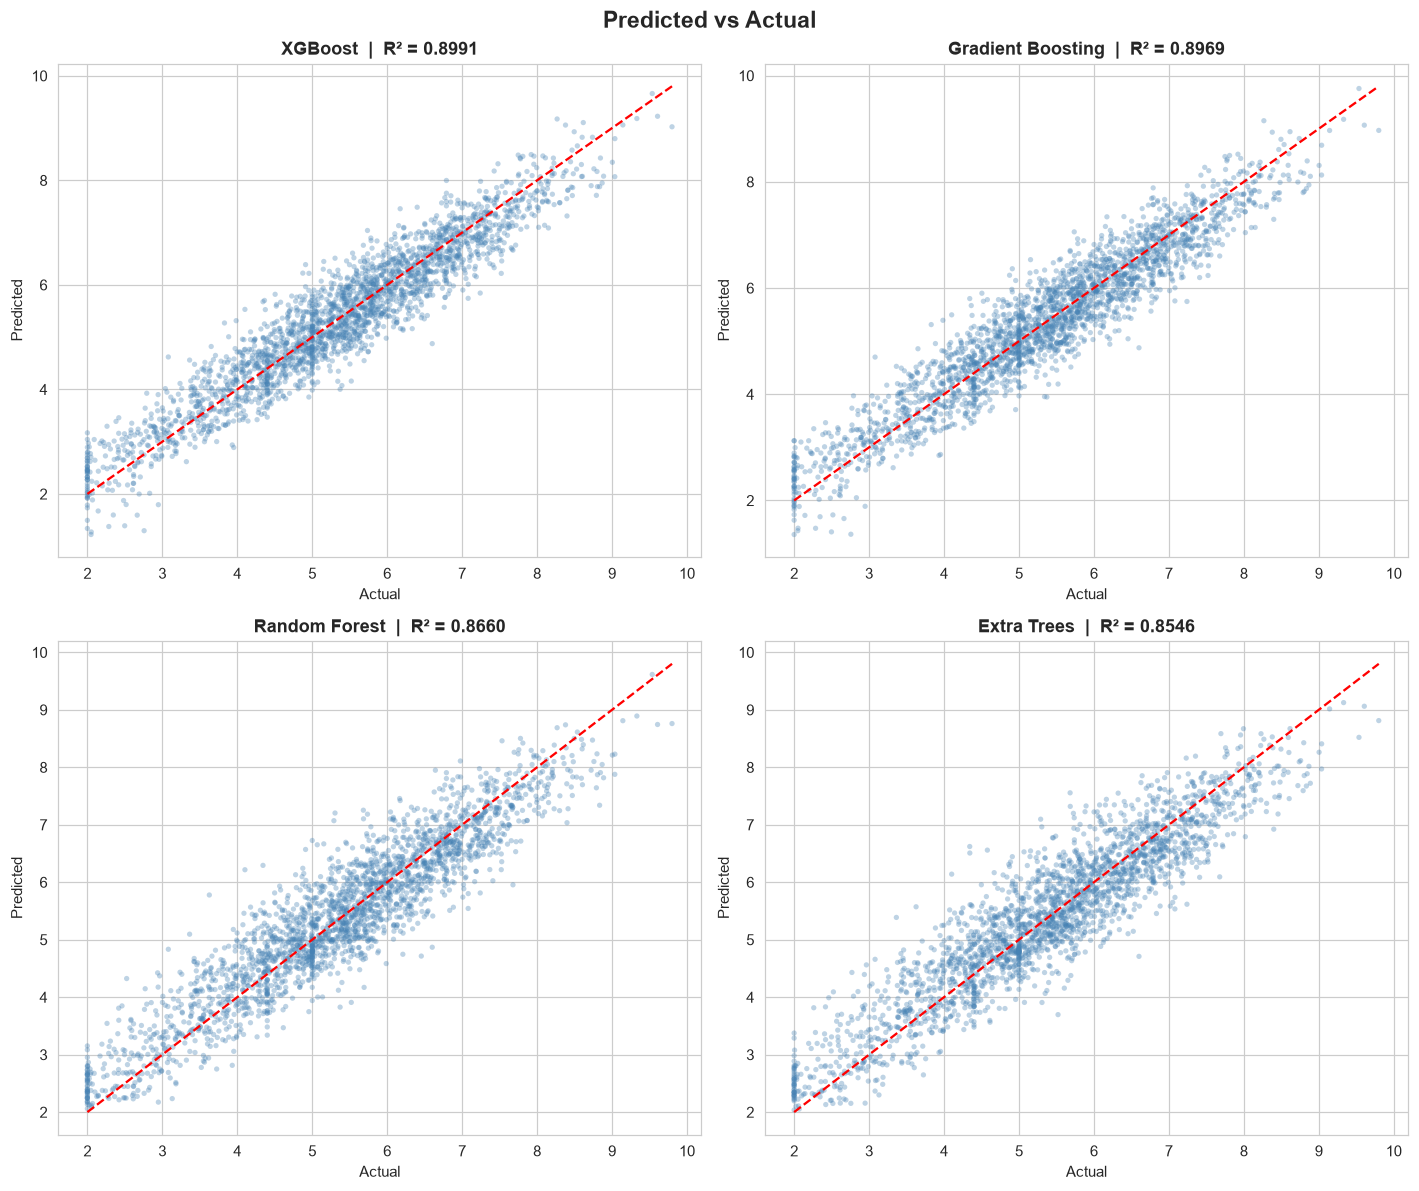

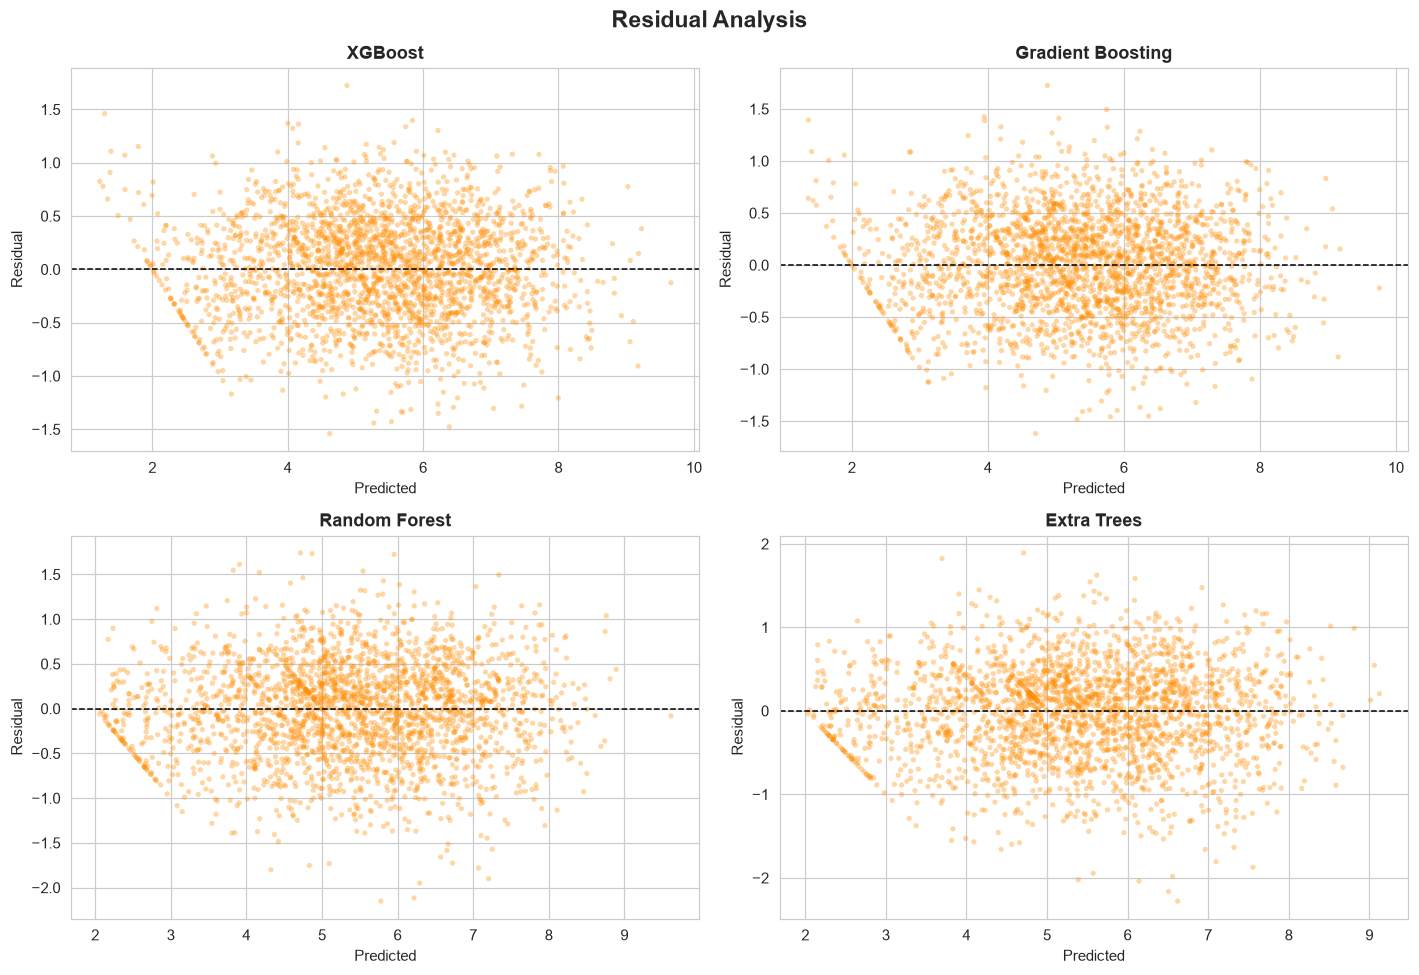

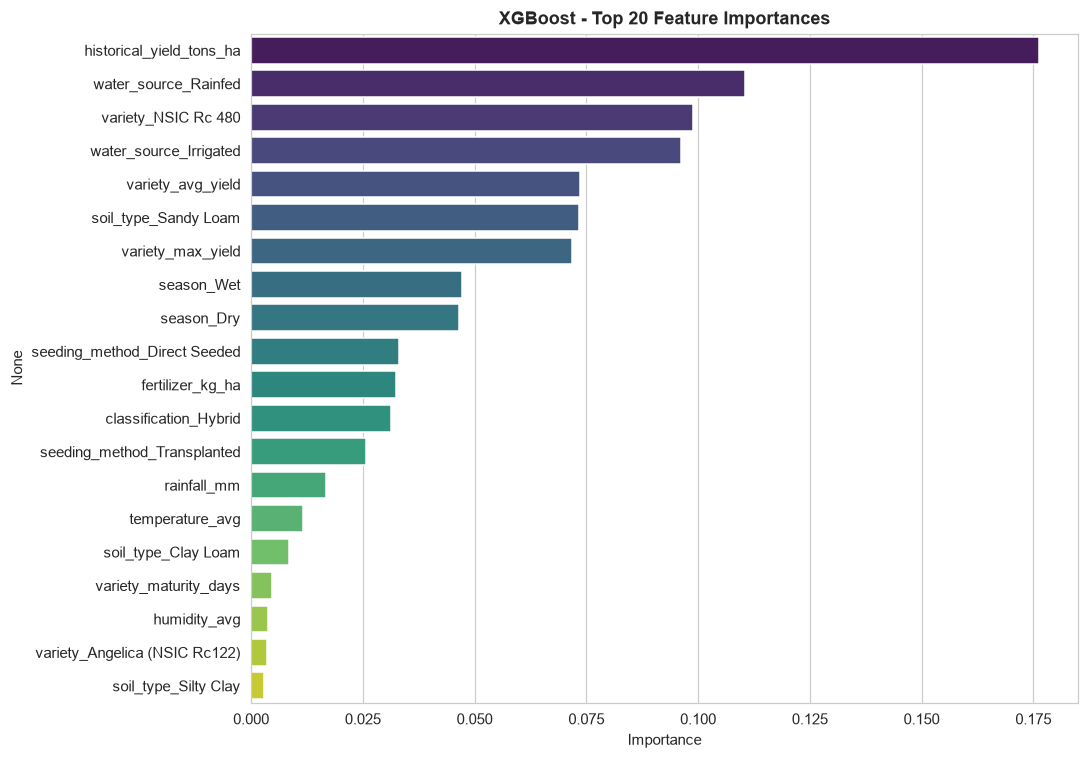

XGBoost              CV RMSE: 0.4642 ± 0.0054
Gradient Boosting    CV RMSE: 0.4663 ± 0.0049
Random Forest        CV RMSE: 0.5427 ± 0.0083
Extra Trees          CV RMSE: 0.5594 ± 0.0059


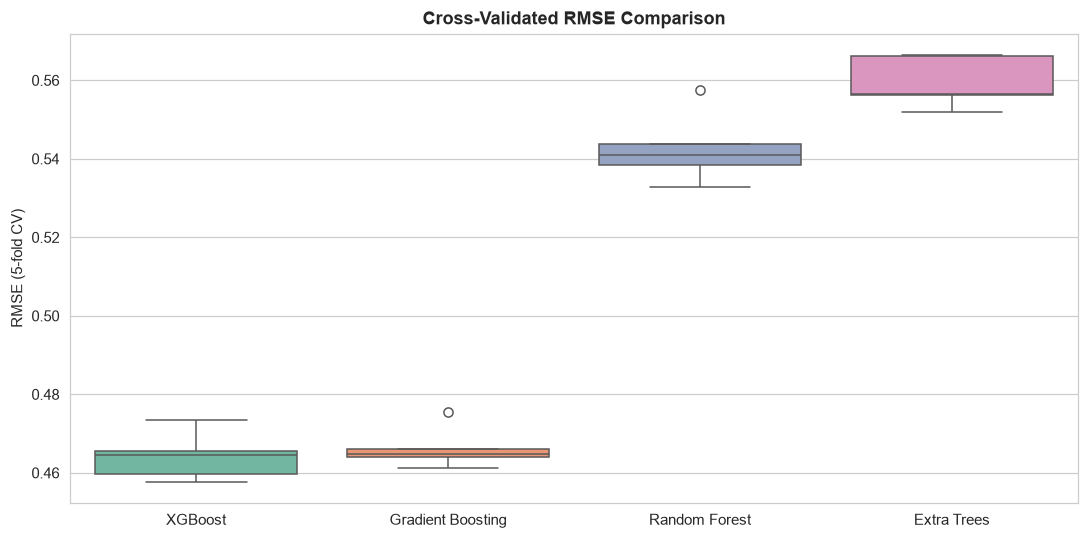

  🏆 BEST MODEL: XGBoost
  XGBoost              RMSE=0.4716  R²=0.8991  <-- WINNER
  Gradient Boosting    RMSE=0.4767  R²=0.8969
  Random Forest        RMSE=0.5436  R²=0.8660
  Extra Trees          RMSE=0.5662  R²=0.8546


In [3]:
# ============================================================
# Cell 1: Imports and Configuration
# ============================================================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, ExtraTreesRegressor

from xgboost import XGBRegressor
from scipy.stats import uniform, randint

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110


# ============================================================
# Cell 2: Load the Dataset
# ============================================================
# Replace with your actual file path
DATA_PATH = "rice_yield_dataset.csv"

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print(df.head())


# ============================================================
# Cell 3: Quick EDA
# ============================================================
print("\n=== Data Info ===")
print(df.info())

print("\n=== Missing Values ===")
print(df.isnull().sum().sum(), "missing cells")

print("\n=== Target Summary ===")
print(df["yield_tons_ha"].describe())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["yield_tons_ha"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Target Distribution")

sns.boxplot(x=df["yield_tons_ha"], ax=axes[1], color="lightgreen")
axes[1].set_title("Target Boxplot")

corr = df.select_dtypes(include=[np.number]).corr()["yield_tons_ha"].drop("yield_tons_ha")
corr.sort_values().tail(12).plot(kind="barh", ax=axes[2], color="coral")
axes[2].set_title("Top Correlations with Target")
plt.tight_layout()
plt.show()


# ============================================================
# Cell 4: Train / Test Split
# ============================================================
TARGET = "yield_tons_ha"
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")


# ============================================================
# Cell 5: Tune XGBoost with RandomizedSearchCV
# ============================================================
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

xgb_param_dist = {
    "n_estimators":      randint(600, 2000),
    "max_depth":         randint(3, 9),
    "learning_rate":     uniform(0.005, 0.05),
    "subsample":         uniform(0.6, 0.4),
    "colsample_bytree":  uniform(0.6, 0.4),
    "min_child_weight":  randint(1, 6),
    "gamma":             uniform(0, 0.3),
    "reg_alpha":         uniform(0, 0.5),
    "reg_lambda":        uniform(0.5, 2.0),
}

xgb_search = RandomizedSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    param_distributions=xgb_param_dist,
    n_iter=60,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE,
    verbose=1,
    n_jobs=-1,
)

xgb_search.fit(X_train, y_train)
print("\nBest XGBoost params:", xgb_search.best_params_)
print(f"Best CV RMSE: {-xgb_search.best_score_:.4f}")

best_xgb = xgb_search.best_estimator_


# ============================================================
# Cell 6: Define the Comparison Models
# ============================================================
models = {
    "XGBoost": best_xgb,
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=800,
        learning_rate=0.02,
        max_depth=4,
        subsample=0.8,
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=600,
        max_depth=None,
        min_samples_split=4,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=600,
        max_depth=None,
        min_samples_split=4,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}


# ============================================================
# Cell 7: Fit Models and Evaluate
# ============================================================
def evaluate(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    rmse = np.sqrt(mean_squared_error(y_te, pred))
    mae  = mean_absolute_error(y_te, pred)
    mape = np.mean(np.abs((y_te - pred) / y_te)) * 100
    r2   = r2_score(y_te, pred)
    return {"RMSE": rmse, "MAE": mae, "MAPE (%)": mape, "R²": r2, "pred": pred}


results = {}
for name, mdl in models.items():
    print(f"\n>>> Training {name} ...")
    results[name] = evaluate(mdl, X_train, y_train, X_test, y_test)

summary = pd.DataFrame(
    {name: {k: v for k, v in r.items() if k != "pred"} for name, r in results.items()}
).T

summary = summary.sort_values("RMSE")
print("\n=== Test-set Performance ===")
print(summary.round(4))

styled = summary.style.background_gradient(cmap="Blues", subset=["RMSE", "MAE", "MAPE (%)"]) \
                  .background_gradient(cmap="Greens_r", subset=["R²"]) \
                  .format({"RMSE": "{:.4f}", "MAE": "{:.4f}",
                           "MAPE (%)": "{:.2f}", "R²": "{:.4f}"})
styled


# ============================================================
# Cell 8: Bar Chart Comparison
# ============================================================
metrics_to_plot = ["RMSE", "MAE", "MAPE (%)", "R²"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
colors = ["#2E86AB", "#E63946", "#F4A261", "#8AB17D"]

for ax, metric in zip(axes.flat, metrics_to_plot):
    data = summary[metric]
    order = data.sort_values(ascending=(metric != "R²")).index
    bars = ax.bar(order, data.loc[order], color=colors)
    ax.set_title(metric, fontsize=13, weight="bold")
    ax.set_ylabel(metric)
    for b, val in zip(bars, data.loc[order]):
        ax.text(b.get_x() + b.get_width()/2, b.get_height(),
                f"{val:.4f}", ha="center", va="bottom", fontsize=9)
    if metric == "R²":
        ax.set_ylim(0, 1.0)

plt.suptitle("Model Comparison on Test Set", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()


# ============================================================
# Cell 9: Predicted vs Actual for Each Model
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (name, res) in zip(axes.flat, results.items()):
    pred = res["pred"]
    ax.scatter(y_test, pred, alpha=0.35, s=12, color="steelblue", edgecolor="none")
    lo, hi = y_test.min(), y_test.max()
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.5)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.set_title(f"{name}  |  R² = {res['R²']:.4f}", weight="bold")
plt.suptitle("Predicted vs Actual", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()


# ============================================================
# Cell 10: Residual Plots
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (name, res) in zip(axes.flat, results.items()):
    resid = y_test.values - res["pred"]
    ax.scatter(res["pred"], resid, alpha=0.35, s=12, color="darkorange", edgecolor="none")
    ax.axhline(0, color="black", linestyle="--", lw=1)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Residual")
    ax.set_title(name, weight="bold")
plt.suptitle("Residual Analysis", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()


# ============================================================
# Cell 11: Feature Importance (XGBoost)
# ============================================================
importances = pd.Series(best_xgb.feature_importances_, index=X.columns)
top = importances.sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 7))
sns.barplot(x=top.values, y=top.index, palette="viridis")
plt.title("XGBoost - Top 20 Feature Importances", weight="bold")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


# ============================================================
# Cell 12: Cross-Validation Comparison (more robust)
# ============================================================
cv_results = {}
for name, mdl in models.items():
    scores = cross_val_score(
        mdl, X, y, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1
    )
    cv_results[name] = -scores
    print(f"{name:<20} CV RMSE: {-scores.mean():.4f} ± {scores.std():.4f}")

plt.figure(figsize=(10, 5))
sns.boxplot(data=pd.DataFrame(cv_results), palette="Set2")
plt.ylabel("RMSE (5-fold CV)")
plt.title("Cross-Validated RMSE Comparison", weight="bold")
plt.tight_layout()
plt.show()


# ============================================================
# Cell 13: Final Verdict
# ============================================================
best_model = summary["RMSE"].idxmin()
print("=" * 55)
print(f"  🏆 BEST MODEL: {best_model}")
print("=" * 55)
for name in summary.index:
    marker = "  <-- WINNER" if name == best_model else ""
    print(f"  {name:<20} RMSE={summary.loc[name,'RMSE']:.4f}  "
          f"R²={summary.loc[name,'R²']:.4f}{marker}")
print("=" * 55)